In [11]:
import numpy as np
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy.linalg import expm

In [3]:
# GLOBAL STYLE SETTINGS (run once)

plt.rcParams.update({

    # --- FONT SIZES ---
    "font.size": 24,              # base font size
    "axes.titlesize": 20,         # title
    "axes.labelsize": 36,         # x/y labels
    "xtick.labelsize": 36,
    "ytick.labelsize": 36,
    "legend.fontsize": 16,

    # --- LINES ---
    "lines.linewidth": 5,
    "lines.markersize": 16,

    # --- FIGURE / AXIS ---
    "figure.figsize": (8, 6),
    "figure.dpi": 120,
    "axes.linewidth": 1.5,        # thicker axis spines

    # --- TICKS ---
    "xtick.major.size": 15,
    "xtick.major.width": 3,
    "ytick.major.size": 15,
    "ytick.major.width": 3,

    # --- LEGEND ---
    "legend.frameon": True,
    "legend.framealpha": 0.8,
    "legend.fancybox": True,

    # --- GRID (optional) ---
    #"axes.grid": True,
    #"grid.alpha": 0.3,
})

In [4]:
def compete_four_pops_multinomial(tau, mu, nu, dt, PopSize=10**8, steps=None):


    # 16 types Pop[TR,VR]
    Pop = np.zeros((4,4), dtype=np.int64)

    
    Pop[0,:] = PopSize//4

    # environment favours VR = 0 → 1 → 2 → 3 → 0 → ...
    Hcycle = [
        np.array([0,1,0,0]),
        np.array([0,0,1,0]),
        np.array([0,0,0,1])
    ]
    Hindex = 0
    H = Hcycle[Hindex]

    next_switch = tau/dt

    freqTR=[]
    AvH=[]
    for k in range(steps):

        # ---- Environment switch ----
        if k > next_switch:
            Hindex = (Hindex + 1) % 3
            H = Hcycle[Hindex]
            next_switch += tau/dt

        # ---- SELECTION ----
        # growth factors for each VR
        w = np.exp(H * dt)  # size 4 vector

        # weighted population
        weighted = Pop * w  # broadcasting over VR
        total_fit = weighted.sum()

        # normalized reproduction probability per (TR,VR)
        P_repro = weighted / total_fit

        # sample next generation
        counts = P_repro.reshape(-1)
        new_counts = np.random.multinomial(PopSize, counts)
        Pop = new_counts.reshape(4,4)

        # ---- TR mutation (sequence mutation) ----
        # each TR mutates with rate mu to uniform TR
        for vr in range(4):
            for tr in range(4):
                count = Pop[tr,vr]
                if count == 0: continue

                # number mutating
                m = np.random.binomial(count, mu*dt)
                if m > 0:
                    Pop[tr,vr] -= m
                    # redistribute among TR=0..3
                    redist = np.random.multinomial(m, [1/4]*4)
                    Pop[:,vr] += redist

        # ---- VR switching (genotype change using DGR(TR)) ----
        for tr in range(4):
            for vr in range(4):
                count = Pop[tr,vr]
                if count == 0: continue

                # number switching genotype
                s = np.random.binomial(count, nu*dt)
                if s == 0:
                    continue

                Pop[tr,vr] -= s
                if tr!=0:
                    Pop[tr,tr]+=s
                else:
                    Pop[tr,:]+=np.random.multinomial(s, [1/4]*4)

        # statistics
        freqTR.append(Pop[:,:] / PopSize)
        AvH.append(np.sum(Pop*H/PopSize))
    return np.array(freqTR)[3*int(tau/dt):],np.array(AvH)[3*int(tau/dt):]


# Fig 3 (a)

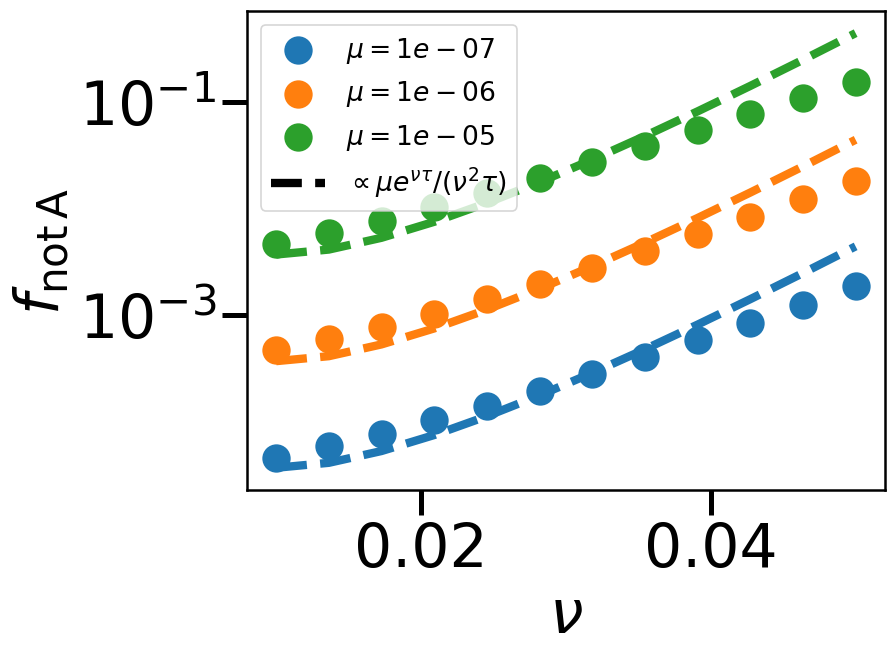

In [5]:
dt = 1e-1
Q = 4
PopSize = 10**12

def compute_f_not_A_nu(nu, mu, tau):
    steps = int(tau/dt*10)
    freq, AvH = compete_four_pops_multinomial(
        tau, mu, nu, dt, PopSize=PopSize, steps=steps
    )
    return np.mean(1 - np.sum(freq[:,0,:], axis=1))


# ---------------------- Dependence on ν (μ fixed) ----------------------
mus = [1e-7, 1e-6, 1e-5]
colors = ["C0", "C1", "C2"]

plt.figure()

nu_lis = np.linspace(0.01,0.05, 12)
tau = 200   # fixed tau

for mu, col in zip(mus, colors):

    # ---- Parallel computation over nu ----
    f_not_A_nu = Parallel(n_jobs=-1)(
        delayed(compute_f_not_A_nu)(nu, mu, tau) for nu in nu_lis
    )
    f_not_A_nu = np.array(f_not_A_nu)

    # Numerical simulation points
    plt.scatter(nu_lis, f_not_A_nu, color=col,
                label=rf"$\mu={mu:g}$")

    # Analytical expectation in the *same* color
    pred = (mu/nu_lis**2/tau) * np.exp(nu_lis*tau)
    plt.plot(nu_lis, pred, '--', color=col)


# Add a single black dashed for legend clarity
plt.plot([], [], '--k', label=r'$\propto \mu e^{\nu \tau}/(\nu^2\tau)$')

#plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$\nu$')
plt.ylabel(r'$f_\mathrm{not\,A}$')
plt.tight_layout()
plt.legend()

#plt.savefig("nutau_big.svg")
#plt.savefig("nutau_big.png")

plt.show()


# Fig 3 (b)

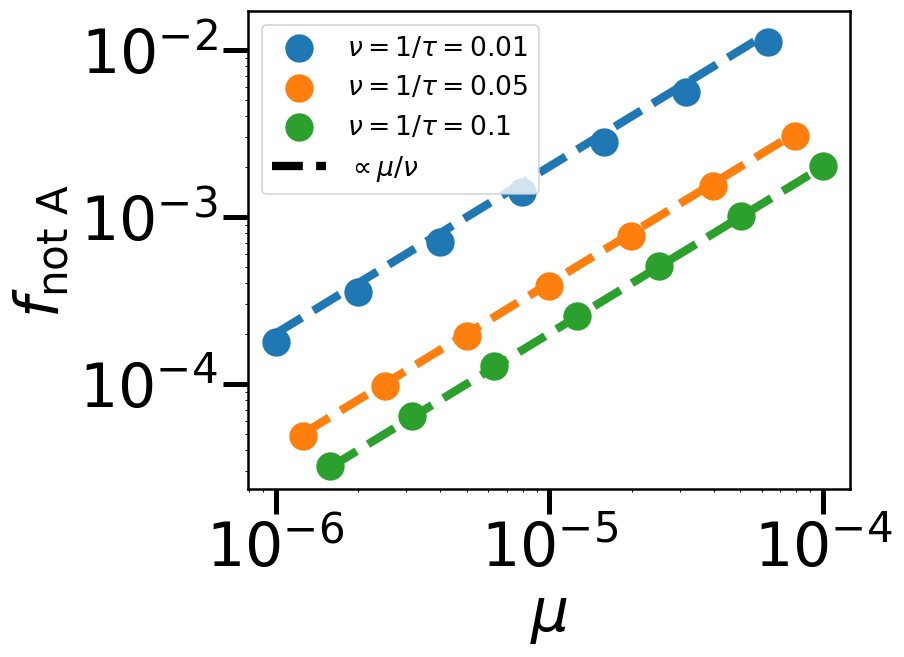

In [6]:
dt = 1e-1
Q = 4
PopSize = 10**12

def compute_f_not_A(mu, nu):
    tau = 1 / nu
    steps = int(tau/dt*10)
    freq, _ = compete_four_pops_multinomial(tau, mu, nu, dt, PopSize=PopSize, steps=steps)
    return np.mean(1 - np.sum(freq[:,0,:], axis=1))

nu_list = [1e-2, 5e-2, 1e-1]

colors = plt.cm.viridis(np.linspace(0, 1, len(nu_list)))  # for scatter + dotted lines



index = 0
already_added_line_legend = False

for i, nu in enumerate(nu_list):
    mu_lis = np.logspace(-6, -4, 21)[index::3]
    index += 1

    # Parallel simulation
    f_not_A = Parallel(n_jobs=-1)(
        delayed(compute_f_not_A)(mu, nu) for mu in mu_lis
    )
    f_not_A = np.array(f_not_A)

    # --- scatter ---
    plt.scatter(mu_lis, f_not_A,
                label=rf"$\nu=1/\tau={nu:g}$")

    # --- dotted line ---
    plt.plot(mu_lis,
             mu_lis/nu * 2,
             '--'
    )

    # Only **one** legend entry for the dotted lines (in black)
if not already_added_line_legend:
        plt.plot([], [], 'k--', label=r'$\propto \mu/\nu$')
        already_added_line_legend = True


plt.xscale("log")
plt.yscale("log")

plt.xlabel(r"$\mu$")
plt.ylabel(r"$f_{\text{not A}}$")

plt.legend()
plt.tight_layout()
#plt.savefig("nutau_1.svg")
#plt.savefig("nutau_1.png")
plt.show()

# Fig 3 (c)

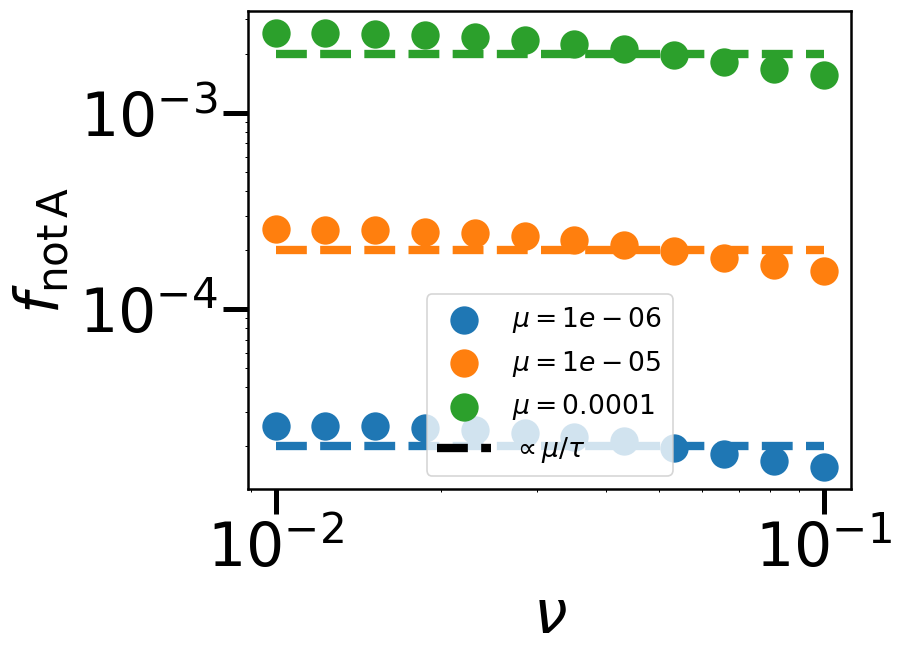

In [7]:
dt = 1e-1
Q = 4
PopSize = 10**12

def compute_f_not_A_nu(nu, mu, tau):
    steps = int(tau/dt*10)
    freq, AvH = compete_four_pops_multinomial(
        tau, mu, nu, dt, PopSize=PopSize, steps=steps
    )
    return np.mean(1 - np.sum(freq[:,0,:], axis=1))


# ---------------------- Dependence on ν (μ fixed) ----------------------
mus = [1e-6, 1e-5, 1e-4]


nu_lis = np.logspace(-2, -1, 12)
tau = 5   # fixed tau

for mu, col in zip(mus, colors):

    # ---- Parallel computation over nu ----
    f_not_A_nu = Parallel(n_jobs=-1)(
        delayed(compute_f_not_A_nu)(nu, mu, tau) for nu in nu_lis
    )
    f_not_A_nu = np.array(f_not_A_nu)

    # Numerical simulation points
    plt.scatter(nu_lis, f_not_A_nu,
                label=rf"$\mu={mu:g}$")

    # Analytical expectation in the *same* color
    pred = (mu*tau) * np.ones_like(nu_lis)*4
    plt.plot(nu_lis, pred, '--')


# Add a single black dashed for legend clarity
plt.plot([], [], '--k', label=r'$\propto \mu/\tau$')

plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$\nu$')
plt.ylabel(r'$f_\mathrm{not\,A}$')

plt.legend()
plt.tight_layout()
#plt.savefig("nutau_small.svg")
#plt.savefig("nutau_small.png")
plt.show()

# Fig 3 (d)

0.1
0.01
0.001


([<matplotlib.axis.XTick at 0x7fb7101fa2f0>,
 [Text(0.01, 0, '$10^{-2}$'),
  Text(1.0, 0, '$10^0$'),
  Text(100.0, 0, '$10^{2}$')])

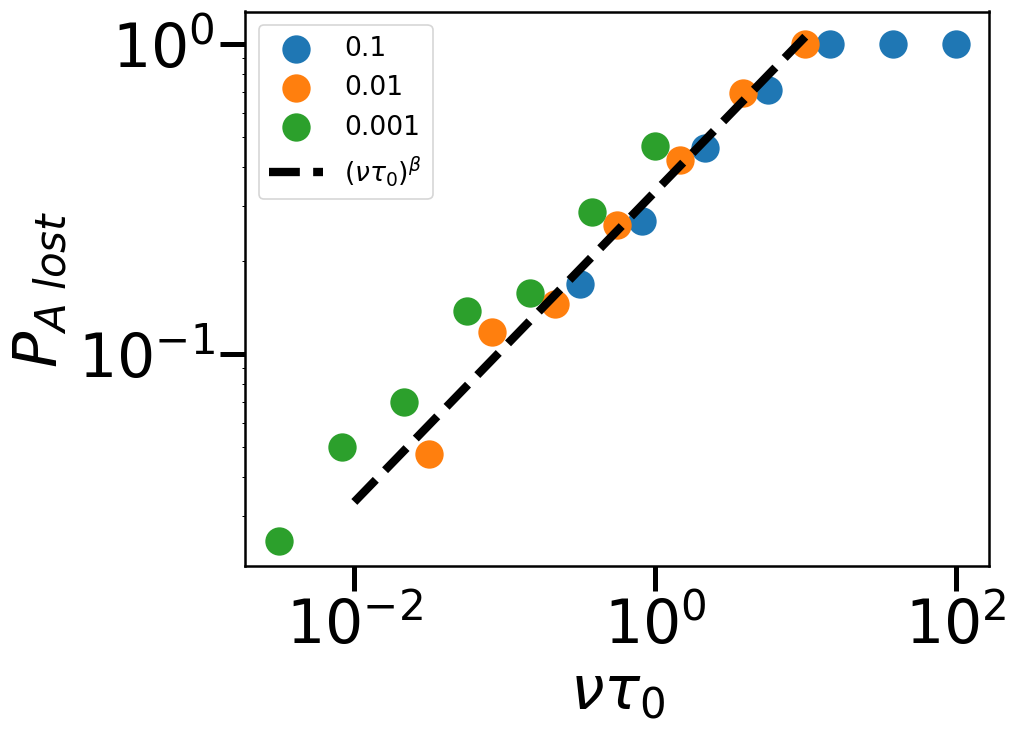

In [9]:
Q = 4
PopSize = 10**12

def compete_four_pops_multinomial(tau, mu, nu, dt, PopSize=10**8, steps=None):


    # 16 types Pop[TR,VR]
    Pop = np.zeros((4,4), dtype=np.int64)

    
    Pop[0,1] = PopSize

    # environment favours VR =  1 → 2 → 3 → 1 → ...
    Hcycle = [
        np.array([0,1,0,0]),
        np.array([0,0,1,0]),
        np.array([0,0,0,1])
    ]
    Hindex = 0
    H = Hcycle[Hindex]

    next_switch = tau/dt

    freqTR=[]
    AvH=[]
    for k in range(steps):
        if k>0 and np.sum((freqTR[-1])[0,:])<0.45:
            break
        # ---- Environment switch ----
        if k > next_switch:
            Hindex = (Hindex + 1) % 3
            H = Hcycle[Hindex]
            next_switch += tau/dt

        # ---- SELECTION ----
        # growth factors for each VR
        w = np.exp(H * dt)  # size 4 vector

        # weighted population
        weighted = Pop * w  # broadcasting over VR
        total_fit = weighted.sum()

        # normalized reproduction probability per (TR,VR)
        P_repro = weighted / total_fit

        # sample next generation
        counts = P_repro.reshape(-1)
        new_counts = np.random.multinomial(PopSize, counts)
        Pop = new_counts.reshape(4,4)

        # ---- TR mutation (sequence mutation) ----
        # each TR mutates with rate mu to uniform TR
        for vr in range(4):
            for tr in range(4):
                count = Pop[tr,vr]
                if count == 0: continue

                # number mutating
                m = np.random.binomial(count, mu*dt)
                if m > 0:
                    Pop[tr,vr] -= m
                    # redistribute among TR=0..3
                    redist = np.random.multinomial(m, [1/4]*4)
                    Pop[:,vr] += redist

        # ---- VR switching (genotype change using DGR(TR)) ----
        for tr in range(4):
            for vr in range(4):
                count = Pop[tr,vr]
                if count == 0: continue

                # number switching genotype
                s = np.random.binomial(count, nu*dt)
                if s == 0:
                    continue

                Pop[tr,vr] -= s
                if tr!=0:
                    Pop[tr,tr]+=s
                else:
                    Pop[tr,:]+=np.random.multinomial(s, [1/4]*4)

        # statistics
        freqTR.append(Pop[:,:] / PopSize)
    return np.sum((freqTR[-1])[0,:]) #freq of A in system

def compute_f_not_A(mu, nu,tau):
    dt=0.1
    steps = max(int(tau/dt),10)
    freqA = compete_four_pops_multinomial(tau, mu, nu, dt=dt, PopSize=PopSize, steps=steps)
    return 1-freqA

# ======================
# paramètres globaux
# ======================
beta = 0.5
mu = 1e-4
nu_values = [1e-1, 1e-2,1e-3]


# ======================
# tirage Pareto de tau
# ======================
def sample_tau(tau0, beta):
    U = np.random.rand()
    return tau0 * U**(-1/beta)


# ======================
# une replica Monte-Carlo
# ======================
def one_replica(tau0, nu):
    tau = sample_tau(tau0, beta)
    f_not_A = compute_f_not_A(mu, nu, tau)
    print(f_not_A)
    return 1.0 if f_not_A > 0.5 else 0.0 #lost A/ A not lost


# ======================
# estimation probabilité pour un tau0
# ======================
def estimate_prob_for_tau0(tau0, nu, Nrep):

    vals = Parallel(n_jobs=-1)(
        delayed(one_replica)(tau0, nu)
        for _ in range(Nrep)
    )

    return np.mean(vals)


# ======================
# calcul global
# ======================
def run_parallel(tau0_values, Nrep=20):

    results = {}

    for nu in nu_values:
        print(nu)
        probs = [
            estimate_prob_for_tau0(tau0, nu, Nrep)
            for tau0 in tau0_values
        ]

        results[nu] = np.array(probs)

    return results



tau0_values = np.logspace(0.5, 3, 7)

results = run_parallel(tau0_values, Nrep=400)

for nu in results:
    plt.scatter(nu*tau0_values,results[nu],label=nu)
x=np.logspace(-2,1,10)
plt.plot(x,x**beta/3,'--k',label=r'$\left(\nu \tau_0\right)^\beta$')
plt.xlabel(r'$\nu \tau_0$')
plt.ylabel(r'$P_{A~lost}$')
plt.legend()

plt.semilogx()
plt.semilogy()
plt.xticks([10**(-2),10**0,10**2],[r'$10^{-2}$',r'$10^0$',r'$10^{2}$'])

#plt.savefig('P_lost_A.svg')

# Fig 3 (e)

In [14]:
# Parameters
mu = 1e-6
nu = 1e-2
Q = 4.0

def Amat(L,mu,nu,Q): # The matrix of rates
    A=np.zeros((L+2,L+2))
    for k in range(0,L+1):
        A[k,k]=-nu/Q**L+nu/Q**(L-k)
        if k>=1:
            A[k,k-1]=mu/Q*(L-k+1)
        if k<L:
            A[k,k+1]=mu/Q*(k+1)
        A[L+1,k]=mu*L*(Q-2)/Q
    A[L+1,L+1]=mu*L*(Q-1)/Q-nu/Q**L
    return A

# Time evaluation
t_eval = np.linspace(0, 40000, 40000)  # dense enough to get first-crossing accurately
dt=t_eval[-1]-t_eval[-2]
# Store results
first_times = []
theo_first_times=[]
Llist=np.unique(np.int64(np.logspace(0,np.log10(400),20)))

for L in Llist:
    # Initial condition
    f0_vec = np.zeros(L+2)
    f0_vec[0] = 1
    
    # Rate matrix
    A = Amat(L, mu, nu, Q)
    
    # Compute solution over time
    # Store solution
    f_t = np.zeros((L+2, len(t_eval)))
    f_t[:,0]=f0_vec[:]
    eA=expm(A * dt)
    for i in range(1,len(t_eval)):
        f_t[:, i] = eA @ f_t[:,i-1]  # exact solution at time t
        f_t[:, i]=f_t[:, i]/np.sum(f_t[:,i])
    # Compute condition: f0 < 0.5 or sum(f1..fL) > 0.5
    f0_vals = f_t[0,:]
    sum_fk = f_t[1:,:].sum(axis=0)
    # Check first time condition is met
    condition = (f0_vals < 0.5) | (sum_fk > 0.5)
    if np.any(condition):
        first_time = t_eval[np.argmax(condition)]  # first True
    else:
        first_time = np.nan  # if never reaches condition
    
    first_times.append(first_time)

[]

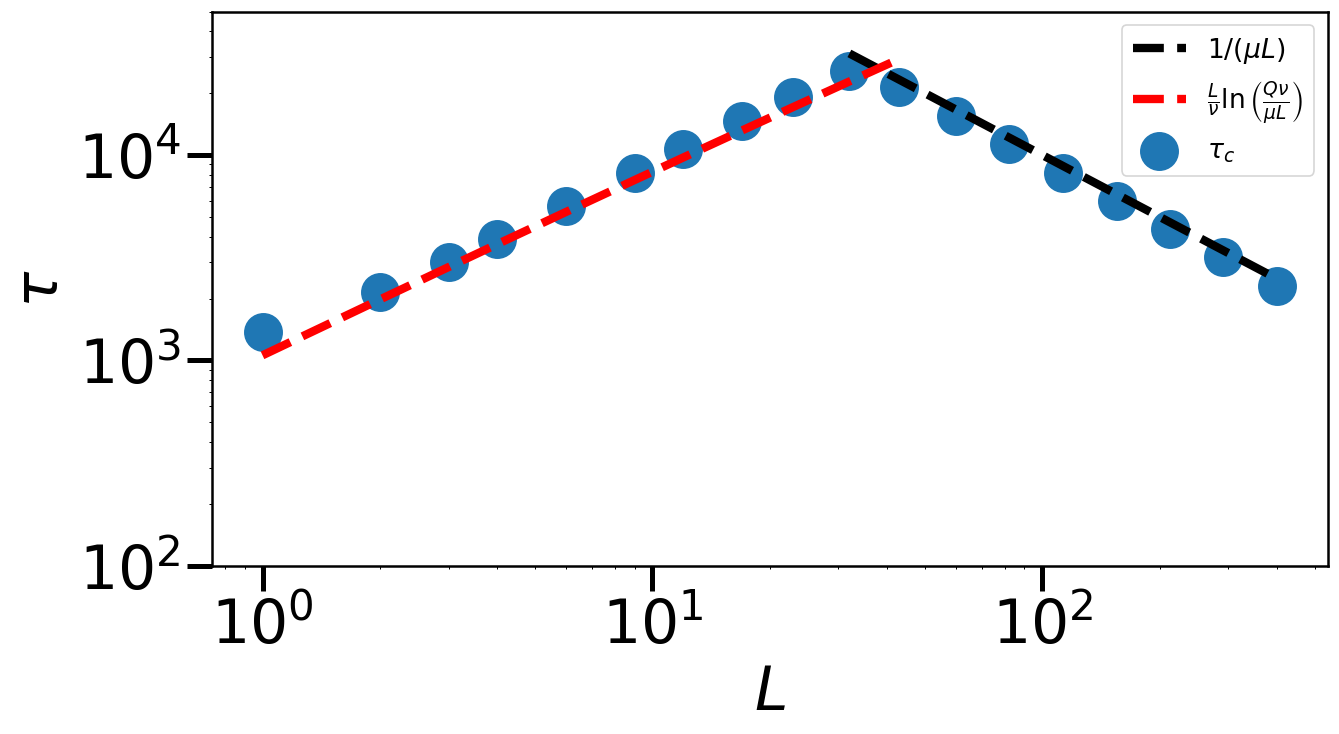

In [15]:
plt.figure(figsize=(12,6))


plt.plot(Llist[-9:],1/mu/Llist[-9:],'--k',label=r'$1/(\mu L)$')
plt.plot(Llist[:11],np.log(Q*nu/mu/Llist[:11])*Llist[:11]/nu,'--r',label=r'$\frac{L}{\nu}\ln \left(\frac{Q \nu}{\mu L} \right)$')

plt.scatter(Llist,np.array(first_times),s=500,label=r'$\tau_c$')
plt.ylim((10**2,5*10**4))
plt.xlabel(r'$L$')
plt.ylabel(r'$\tau$')
plt.legend()
plt.semilogy()
plt.semilogx()
#plt.savefig('Critical_loss_time_V0.svg')
#plt.savefig('Critical_loss_time.png')